# Phase 2 — Opinion Mining & Traditional Machine Learning, Transformer model training and evaluation
## NLP Pipeline · Movie Review Sentiment Analysis


### Phase 2 Objectives

This phase bridges **unsupervised lexicon-based opinion mining** and **supervised machine learning**, allowing us to directly compare the two paradigms on the same dataset.

| # | Section | Technique | Library |
|---|---------|-----------|--------|
| 0 | Environment Setup | Imports & config | — |
| 1 | Data Loading | Load Phase 1 CSV | Pandas |
| 2 | Lexicon-Based Opinion Mining | VADER compound scoring | NLTK |
| 3 | Feature Engineering | TF-IDF (unigrams + bigrams) | Scikit-Learn |
| 4 | Model Training | Logistic Regression | Scikit-Learn |
| 5 | Evaluation — ML Model | Classification report + confusion matrix | Scikit-Learn / Seaborn |
| 6 | Head-to-Head Comparison | VADER vs. Logistic Regression | — |

---

### Methodology Overview

```
movie_reviews_phase1_cleaned.csv
         │
         ├──► VADER (Rule-Based) ──────────────────► vader_prediction
         │                                                  │
         └──► TF-IDF Vectoriser ──► Logistic Regression ──► lr_prediction
                                                            │
                                               Compare both against sentiment_label
```

---
## Section 0 — Environment Setup

All imports are grouped by function. A single `RANDOM_SEED` constant ensures every stochastic step (train/test split, model initialisation) is reproducible across runs.

In [1]:
# ── Standard library ─────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

# ── Data manipulation ────────────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Visualisation ────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# ── NLP — NLTK VADER (lexicon-based sentiment) ───────────────────────────────
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
nltk.download('vader_lexicon', quiet=True)   # download lexicon once

# ── Scikit-Learn — feature engineering ──────────────────────────────────────
from sklearn.feature_extraction.text import TfidfVectorizer

# ── Scikit-Learn — model selection ──────────────────────────────────────────
from sklearn.model_selection import train_test_split

# ── Scikit-Learn — model ─────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# ── Scikit-Learn — evaluation ────────────────────────────────────────────────
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# ── Global aesthetics ─────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.titlesize'   : 13,
    'axes.titleweight' : 'bold',
    'axes.labelsize'   : 11,
})

# ── Shared colour palette (consistent with Phase 1) ───────────────────────────
PALETTE = {
    'Negative' : '#E05C5C',
    'Neutral'  : '#F5A623',
    'Positive' : '#4CAF82',
}
LABEL_ORDER = ['Negative', 'Neutral', 'Positive']

# ── Reproducibility ───────────────────────────────────────────────────────────
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print('  Environment ready.')

  Environment ready.


---
## Section 1 — Data Loading

We load the CSV produced at the end of Phase 1. Two columns drive everything in this phase:

| Column | Type | Description |
|--------|------|-------------|
| `cleaned_text` | `str` | Lowercased, URL/punctuation/stopword-free review text |
| `sentiment_label` | `str` | Ground-truth class: **Negative / Neutral / Positive** |

> A guard is included to catch any residual nulls so this phase fails fast with a clear message rather than silently producing wrong results downstream.

In [2]:
# ── Load Phase 1 output ───────────────────────────────────────────────────────
CSV_PATH = 'movie_reviews_phase1_cleaned.csv'   
df = pd.read_csv(CSV_PATH)

print(f'Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Columns: {list(df.columns)}')

Loaded: 87,906 rows × 12 columns
Columns: ['review_id', 'reviewer', 'movie', 'rating', 'review_summary', 'review_date', 'spoiler_tag', 'review_detail', 'helpful', 'sentiment_label', 'cleaned_text', 'review_length']


In [3]:
# ── Data integrity guard ──────────────────────────────────────────────────────
# Phase 2 requires both critical columns to be fully populated.
# Fail immediately with a descriptive error rather than propagating NaN-related
# bugs into the vectoriser or model training steps.

REQUIRED_COLS = ['cleaned_text', 'sentiment_label']

for col in REQUIRED_COLS:
    if col not in df.columns:
        raise KeyError(
            f"Column '{col}' not found. "
            "Ensure you are loading the Phase 1 cleaned CSV."
        )
    null_count = df[col].isnull().sum()
    if null_count > 0:
        raise ValueError(
            f"Column '{col}' contains {null_count} null values. "
            "Run Phase 1 cleaning again before proceeding."
        )

# Fill any empty strings in cleaned_text with a single space
# (TfidfVectorizer raises an error on empty strings)
df['cleaned_text'] = df['cleaned_text'].fillna('').replace('', ' ')

print('  Data integrity check passed — no nulls in critical columns.')

  Data integrity check passed — no nulls in critical columns.


In [4]:
# ── Quick preview of the data ─────────────────────────────────────────────────
df[['cleaned_text', 'sentiment_label']].head(5)

,cleaned_text,sentiment_label
0,seeing tarantino kill bill vol got watch vol n...,Positive
1,critics prove morons movie definitely best see...,Positive
2,film done many times already guy confess true ...,Negative
3,chris farley one favorite comedians forever mi...,Positive
4,love anime series complaint lasted one season ...,Positive


In [5]:
# ── Class distribution (reminder from Phase 1) ────────────────────────────────
# Important context for interpreting model metrics:
# any class imbalance here will affect precision/recall per class.
class_counts = df['sentiment_label'].value_counts().reindex(LABEL_ORDER)
class_pcts   = (class_counts / len(df) * 100).round(1)

print('Ground-truth class distribution:')
for label, cnt, pct in zip(LABEL_ORDER, class_counts, class_pcts):
    bar = '█' * int(pct / 2)
    print(f'  {label:<10} {cnt:>6,}  ({pct:>5.1f}%)  {bar}')

Ground-truth class distribution:
  Negative   18,235  ( 20.7%)  ██████████
  Neutral    11,770  ( 13.4%)  ██████
  Positive   57,901  ( 65.9%)  ████████████████████████████████


---
## Section 2 — Lexicon-Based Opinion Mining (VADER)

### What is VADER?

**VADER** (Valence Aware Dictionary and sEntiment Reasoner) is a rule-based sentiment analyser built specifically for social media and short-form text. It assigns four scores to any input string:

| Score | Meaning |
|-------|---------|
| `pos` | Proportion of text that is positive |
| `neg` | Proportion of text that is negative |
| `neu` | Proportion of text that is neutral |
| `compound` | Normalised aggregate score ∈ **[-1, +1]** |

### Mapping Rule (as specified)

| Compound Score | Predicted Sentiment |
|---------------|--------------------|
| ≥ 0.05 | **Positive** |
| ≤ -0.05 | **Negative** |
| -0.05 < score < 0.05 | **Neutral** |

> **Important caveat:** VADER was designed for *raw* text and performs best with punctuation, capitalisation, and exclamation marks intact. Our `cleaned_text` has had these stripped in Phase 1, which means VADER scores here represent a **lower bound** on its true capability. This makes the comparison with the ML model especially interesting — the ML model was *trained* on the same cleaned text.

In [6]:
# ── Initialise the VADER Sentiment Intensity Analyser ────────────────────────
# SentimentIntensityAnalyzer loads the built-in lexicon (~7,500 word-sentiment
# associations with valence modifiers like "very", "but", "!").
sia = SentimentIntensityAnalyzer()


def get_vader_compound(text: str) -> float:
    """
    Return the VADER compound score for a single text string.

    The compound score is a single value normalised between -1 (most negative)
    and +1 (most positive). It is the best single metric for overall sentiment.

    Parameters
    ----------
    text : str
        Preprocessed review text.

    Returns
    -------
    float
        VADER compound score in [-1, +1].
    """
    if not isinstance(text, str) or not text.strip():
        return 0.0    # neutral default for empty / invalid input
    return sia.polarity_scores(text)['compound']


def map_compound_to_label(score: float) -> str:
    """
    Map a VADER compound score to a three-class sentiment label.

    Thresholds follow the VADER author's recommended defaults:
        compound >= +0.05  → Positive
        compound <= -0.05  → Negative
        otherwise          → Neutral

    Parameters
    ----------
    score : float
        VADER compound score.

    Returns
    -------
    str
        One of 'Positive', 'Neutral', or 'Negative'.
    """
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'


# ── Apply VADER to every review ───────────────────────────────────────────────
print('  Running VADER on all reviews …')
df['vader_compound']   = df['cleaned_text'].apply(get_vader_compound)
df['vader_prediction'] = df['vader_compound'].apply(map_compound_to_label)
print('  VADER scoring complete.')

# ── Quick sanity-check ────────────────────────────────────────────────────────
df[['cleaned_text', 'sentiment_label', 'vader_compound', 'vader_prediction']].head(6)

  Running VADER on all reviews …
  VADER scoring complete.


,cleaned_text,sentiment_label,vader_compound,vader_prediction
0,seeing tarantino kill bill vol got watch vol n...,Positive,0.4550,Positive
1,critics prove morons movie definitely best see...,Positive,0.9933,Positive
2,film done many times already guy confess true ...,Negative,0.9602,Positive
3,chris farley one favorite comedians forever mi...,Positive,0.9388,Positive
4,love anime series complaint lasted one season ...,Positive,0.9735,Positive
5,excellent good fair poor watching aviator knew...,Positive,0.9904,Positive


In [7]:
# ── Calculate VADER accuracy against ground-truth labels ─────────────────────
vader_accuracy = accuracy_score(df['sentiment_label'], df['vader_prediction'])

print('━' * 55)
print('  VADER LEXICON-BASED SENTIMENT — ACCURACY')
print('━' * 55)
print(f'  Overall Accuracy : {vader_accuracy:.4f}  ({vader_accuracy*100:.2f}%)')
print()

# Per-class breakdown — useful to understand where VADER struggles
print('  Per-class prediction distribution (VADER):')
vader_dist = df['vader_prediction'].value_counts().reindex(LABEL_ORDER, fill_value=0)
for label, cnt in vader_dist.items():
    pct = cnt / len(df) * 100
    print(f'    {label:<10}  {cnt:>6,}  ({pct:.1f}%)')
print()

# Full per-class report for VADER
print('  VADER Classification Report:')
print(classification_report(
    df['sentiment_label'],
    df['vader_prediction'],
    target_names = LABEL_ORDER,
    zero_division= 0
))

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  VADER LEXICON-BASED SENTIMENT — ACCURACY
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Overall Accuracy : 0.6658  (66.58%)

  Per-class prediction distribution (VADER):
    Negative    18,471  (21.0%)
    Neutral        614  (0.7%)
    Positive    68,821  (78.3%)

  VADER Classification Report:
              precision    recall  f1-score   support

    Negative       0.45      0.45      0.45     18235
     Neutral       0.17      0.01      0.02     11770
    Positive       0.73      0.87      0.79     57901

    accuracy                           0.67     87906
   macro avg       0.45      0.44      0.42     87906
weighted avg       0.60      0.67      0.62     87906



###  VADER Analysis Notes

Key observations to note for your report:

- **Neutral class:** VADER typically struggles most with the Neutral class. Reviews rated 5–6 often contain both positive and negative language, pushing the compound score away from the narrow `(-0.05, +0.05)` neutral band.
- **Preprocessing penalty:** Our `cleaned_text` removed punctuation and casing — both signals VADER's rule engine relies on (e.g. `!!!` multiplies intensity). Expect VADER accuracy to be modestly lower here than it would be on raw text.
- **No training required:** VADER requires zero labelled data, making it a strong zero-shot baseline.

---
## Section 3 — Feature Engineering (TF-IDF Vectorisation)

### Why TF-IDF?

Raw text cannot be fed directly into a scikit-learn model — it must be converted to a numerical matrix. **TF-IDF** (Term Frequency–Inverse Document Frequency) assigns a weight to each word that reflects:

$$\text{TF-IDF}(t, d) = \underbrace{\frac{f_{t,d}}{\sum_k f_{k,d}}}_{\text{TF: how often in doc}} \times \underbrace{\log\frac{N}{n_t}}_{\text{IDF: how rare across corpus}}$$

Words that appear frequently in one review but rarely across all reviews get a **high score** — they are informative. Words that appear everywhere (despite stopword removal) get a **low score**.

### Design Choices

| Parameter | Value | Reason |
|-----------|-------|--------|
| `ngram_range` | `(1, 2)` | Captures unigrams (`film`) **and** bigrams (`really boring`) — bigrams preserve phrase-level context |
| `max_features` | `5000` | Caps the vocabulary; prevents memory explosion and reduces noise from rare terms |
| `sublinear_tf` | `True` | Applies `log(1 + tf)` to dampen the effect of very frequent terms |
| `min_df` | `3` | Ignore terms that appear in fewer than 3 documents — removes pure noise/typos |

In [8]:
# ── Define feature matrix X and target vector y ───────────────────────────────
X_text = df['cleaned_text']         # raw text series (vectoriser input)
y      = df['sentiment_label']      # ground-truth labels

# ── Train / Test split (80 / 20) ─────────────────────────────────────────────
# CRITICAL: We split BEFORE fitting the vectoriser.
# Fitting on the full dataset would cause data leakage — the vectoriser would
# learn IDF statistics from test documents, giving the model an unfair advantage.
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size    = 0.20,
    random_state = RANDOM_SEED,
    stratify     = y         # maintain class proportions in both splits
)

print(f'Training set : {len(X_train_text):,} reviews  '
      f'({len(X_train_text)/len(df)*100:.0f}%)')
print(f'Test set     : {len(X_test_text):,} reviews  '
      f'({len(X_test_text)/len(df)*100:.0f}%)')

# Verify stratification held
print('\nClass distribution check (should match overall dataset):')
train_dist = y_train.value_counts(normalize=True).reindex(LABEL_ORDER)
test_dist  = y_test.value_counts(normalize=True).reindex(LABEL_ORDER)
check_df   = pd.DataFrame({'Train %': (train_dist*100).round(1),
                            'Test %' : (test_dist*100).round(1)})
print(check_df.to_string())

Training set : 70,324 reviews  (80%)
Test set     : 17,582 reviews  (20%)

Class distribution check (should match overall dataset):
                 Train %  Test %
sentiment_label                 
Negative            20.7    20.7
Neutral             13.4    13.4
Positive            65.9    65.9


In [9]:
# ── Initialise TF-IDF Vectoriser ──────────────────────────────────────────────
tfidf_vectorizer = TfidfVectorizer(
    ngram_range  = (1, 2),    # unigrams + bigrams
    max_features = 5000,      # top 5,000 terms by corpus TF-IDF
    sublinear_tf = True,      # log-normalise TF to dampen very frequent terms
    min_df       = 3,         # ignore terms in < 3 documents (noise filter)
    strip_accents= 'unicode', # normalise accented characters
    analyzer     = 'word',    # tokenise on word boundaries
)

# ── Fit on TRAINING data only, then transform both splits ────────────────────
# .fit_transform(train) learns the vocabulary + IDF weights from training docs.
# .transform(test)      applies the SAME learned vocabulary to test docs.
# This mirrors real-world deployment: the model never 'sees' test data during fitting.
X_train = tfidf_vectorizer.fit_transform(X_train_text)
X_test  = tfidf_vectorizer.transform(X_test_text)

print(f'TF-IDF matrix — Training : {X_train.shape}  '
      f'(rows=reviews, cols=features)')
print(f'TF-IDF matrix — Test     : {X_test.shape}')
print(f'Vocabulary size           : {len(tfidf_vectorizer.vocabulary_):,} terms')
print(f'Matrix density            : '
      f'{X_train.nnz / (X_train.shape[0] * X_train.shape[1]) * 100:.3f}%  ')

TF-IDF matrix — Training : (70324, 5000)  (rows=reviews, cols=features)
TF-IDF matrix — Test     : (17582, 5000)
Vocabulary size           : 5,000 terms
Matrix density            : 1.758%  (sparse — most entries are 0)


In [10]:
# ── Inspect the top TF-IDF features ──────────────────────────────────────────
# Retrieve feature names and their mean TF-IDF weight across the training set.
# High mean weight = the term consistently distinguishes documents.
feature_names    = tfidf_vectorizer.get_feature_names_out()
mean_tfidf       = np.asarray(X_train.mean(axis=0)).flatten()
top_n            = 20

top_indices  = mean_tfidf.argsort()[::-1][:top_n]
top_features = pd.DataFrame({
    'Feature'     : feature_names[top_indices],
    'Mean TF-IDF' : mean_tfidf[top_indices].round(5),
    'Is Bigram'   : ['Yes' if ' ' in f else 'No'
                     for f in feature_names[top_indices]]
})

print(f'Top {top_n} features by mean TF-IDF weight (training set):')
print(top_features.to_string(index=False))

Top 20 features by mean TF-IDF weight (training set):
Feature  Mean TF-IDF Is Bigram
  movie      0.04149        No
   film      0.03590        No
    one      0.02814        No
   like      0.02523        No
   good      0.02362        No
    see      0.02135        No
  story      0.02026        No
 really      0.02018        No
  great      0.02003        No
  would      0.01975        No
   time      0.01966        No
   well      0.01938        No
   even      0.01781        No
   much      0.01742        No
   also      0.01685        No
 people      0.01678        No
 movies      0.01647        No
    get      0.01627        No
  first      0.01625        No
  think      0.01605        No


---
## Section 4 — Model Training (Logistic Regression)

In [11]:
from sklearn.model_selection import GridSearchCV

# ── 1. Define the Hyperparameter Grid ─────────────────────────────────────────
param_grid = {
    'C': [0.1, 1.0, 10.0, 50.0],
    'class_weight': ['balanced', None]
}

# ── 2. Initialise Base Logistic Regression ────────────────────────────────────
base_lr = LogisticRegression(
    solver='lbfgs', 
    max_iter=1000, 
    random_state=RANDOM_SEED  # Using your exact variable
)

# ── 3. Set up Grid Search Cross-Validation ────────────────────────────────────
print('  Running Grid Search Tuning (Testing 8 combinations)... this may take a few minutes …')
grid_search = GridSearchCV(
    estimator=base_lr,
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    verbose=2,
    n_jobs=-1                 
)

# ── 4. Train the models ───────────────────────────────────────────────────────
grid_search.fit(X_train, y_train)
print('  Tuning complete.')
print(f'  Best Parameters Found: {grid_search.best_params_}')

# ── 5. Save Model & Quick training-set accuracy (sanity check only) ───────────
lr_model = grid_search.best_estimator_


train_acc = lr_model.score(X_train, y_train)
print(f'\n  Training accuracy (sanity check): {train_acc:.4f}  ({train_acc*100:.2f}%)')

  Running Grid Search Tuning (Testing 8 combinations)... this may take a few minutes …
Fitting 3 folds for each of 8 candidates, totalling 24 fits
  Tuning complete.
  Best Parameters Found: {'C': 1.0, 'class_weight': None}

  Training accuracy (sanity check): 0.8296  (82.96%)


---
## Section 5 — Model Evaluation (Traditional Machine Learning)

We evaluate the Logistic Regression model on the **held-out test set** using three complementary tools:

1. **Classification Report** — per-class Precision, Recall, F1-Score, and Support
2. **Confusion Matrix Heatmap** — visual breakdown of correct vs incorrect predictions
3. **Per-class confidence visualisation** — where the model is most / least certain

### Metric Definitions

| Metric | Formula | Meaning |
|--------|---------|--------|
| **Precision** | TP / (TP + FP) | Of all predicted Positive, how many were actually Positive? |
| **Recall** | TP / (TP + FN) | Of all actual Positive, how many did we catch? |
| **F1-Score** | 2 × (P × R) / (P + R) | Harmonic mean — balances precision and recall |
| **Support** | — | Number of actual instances of that class in the test set |

In [12]:
# ── Generate predictions on the held-out test set ────────────────────────────
y_pred     = lr_model.predict(X_test)
lr_accuracy = accuracy_score(y_test, y_pred)

print('━' * 55)
print('  LOGISTIC REGRESSION — TEST SET RESULTS')
print('━' * 55)
print(f'  Overall Accuracy : {lr_accuracy:.4f}  ({lr_accuracy*100:.2f}%)')
print()

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  LOGISTIC REGRESSION — TEST SET RESULTS
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Overall Accuracy : 0.7954  (79.54%)



In [13]:
# ── Full classification report ────────────────────────────────────────────────
# target_names enforces the display order Negative → Neutral → Positive.
# zero_division=0 prevents warnings when a class has no predicted samples.

report_str = classification_report(
    y_test,
    y_pred,
    target_names  = LABEL_ORDER,
    zero_division = 0
)

print('  Classification Report (Logistic Regression):')
print('  ' + report_str.replace('\n', '\n  '))

  Classification Report (Logistic Regression):
                precision    recall  f1-score   support
  
      Negative       0.76      0.71      0.73      3647
       Neutral       0.43      0.19      0.27      2354
      Positive       0.83      0.94      0.89     11581
  
      accuracy                           0.80     17582
     macro avg       0.67      0.62      0.63     17582
  weighted avg       0.76      0.80      0.77     17582
  


In [14]:
# ── Parse report into a styled DataFrame for clean notebook display ───────────
report_dict = classification_report(
    y_test, y_pred,
    target_names  = LABEL_ORDER,
    zero_division = 0,
    output_dict   = True      # returns a dict instead of a string
)

# Keep only per-class rows (drop 'accuracy', 'macro avg', 'weighted avg')
report_df = (
    pd.DataFrame(report_dict)
    .T
    .loc[LABEL_ORDER, ['precision', 'recall', 'f1-score', 'support']]
    .rename(columns={'f1-score': 'F1-Score',
                     'precision': 'Precision',
                     'recall': 'Recall',
                     'support': 'Support'})
)
report_df['Support'] = report_df['Support'].astype(int)

# Gradient colour on numeric columns for instant visual scanning
report_df.style \
    .format({'Precision': '{:.3f}', 'Recall': '{:.3f}', 'F1-Score': '{:.3f}', 'Support': '{:,}'}) \
    .background_gradient(cmap='RdYlGn', subset=['Precision', 'Recall', 'F1-Score'], vmin=0, vmax=1) \
    .set_caption('Logistic Regression — Per-Class Metrics (Test Set)')

,Precision,Recall,F1-Score,Support
Negative,0.758,0.713,0.735,"3,647"
Neutral,0.431,0.194,0.267,"2,354"
Positive,0.835,0.944,0.886,"11,581"


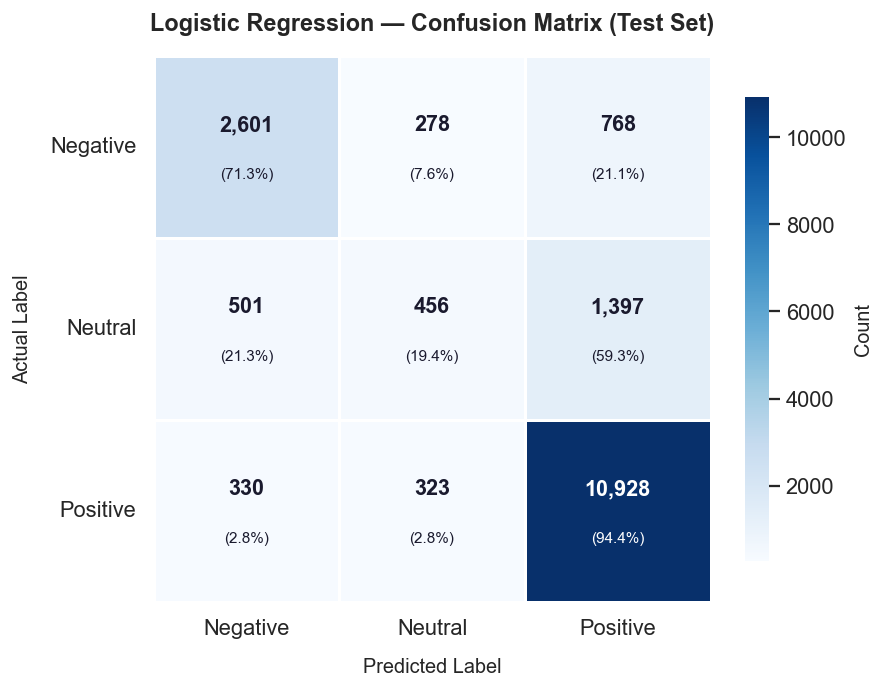

  Figure saved → 5_lr_confusion_matrix.png


In [15]:
# ── Confusion Matrix Heatmap ──────────────────────────────────────────────────
# Rows = actual class  |  Columns = predicted class
# Diagonal cells = correct predictions (want these to be high)
# Off-diagonal  = misclassifications (want these to be low)

def plot_confusion_matrix(
    y_true      : pd.Series,
    y_pred      : np.ndarray,
    labels      : list,
    title       : str = 'Confusion Matrix',
    save_path   : str = None
) -> None:
    """
    Plot a fully annotated confusion matrix heatmap.

    Each cell shows:
      • Raw count (large, bold)
      • Row percentage (smaller, below) — "of all Actual X, N% were predicted Y"

    Parameters
    ----------
    y_true    : pd.Series    Ground-truth labels.
    y_pred    : np.ndarray   Model predictions.
    labels    : list         Ordered class labels for axes.
    title     : str          Figure title.
    save_path : str          File path to save PNG (optional).
    """
    cm      = confusion_matrix(y_true, y_pred, labels=labels)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)  # row-normalise

    fig, ax = plt.subplots(figsize=(7, 5.5))

    # Draw heatmap using raw counts for colour intensity
    sns.heatmap(
        cm,
        annot       = False,        # we build custom annotations below
        fmt         = '',
        cmap        = 'Blues',
        linewidths  = 0.8,
        linecolor   = 'white',
        xticklabels = labels,
        yticklabels = labels,
        cbar_kws    = {'label': 'Count', 'shrink': 0.85},
        ax          = ax,
    )

    # ── Custom dual-line cell annotations ────────────────────────────────────
    # Top line  : raw count (bold)
    # Bottom line : row-normalised percentage
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            count   = cm[i, j]
            pct     = cm_norm[i, j] * 100
            # Choose text colour based on cell background brightness
            text_colour = 'white' if count > cm.max() * 0.6 else '#1a1a2e'
            ax.text(
                j + 0.5, i + 0.38,
                f'{count:,}',
                ha='center', va='center',
                fontsize=12, fontweight='bold', color=text_colour
            )
            ax.text(
                j + 0.5, i + 0.65,
                f'({pct:.1f}%)',
                ha='center', va='center',
                fontsize=8.5, color=text_colour
            )

    # ── Labels & styling ─────────────────────────────────────────────────────
    ax.set_title(title, pad=14)
    ax.set_xlabel('Predicted Label', labelpad=10)
    ax.set_ylabel('Actual Label', labelpad=10)
    ax.tick_params(axis='x', rotation=0)
    ax.tick_params(axis='y', rotation=0)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_confusion_matrix(
    y_test, y_pred,
    labels    = LABEL_ORDER,
    title     = 'Logistic Regression — Confusion Matrix (Test Set)',
    save_path = '5_lr_confusion_matrix.png'
)
print('  Figure saved → 5_lr_confusion_matrix.png')

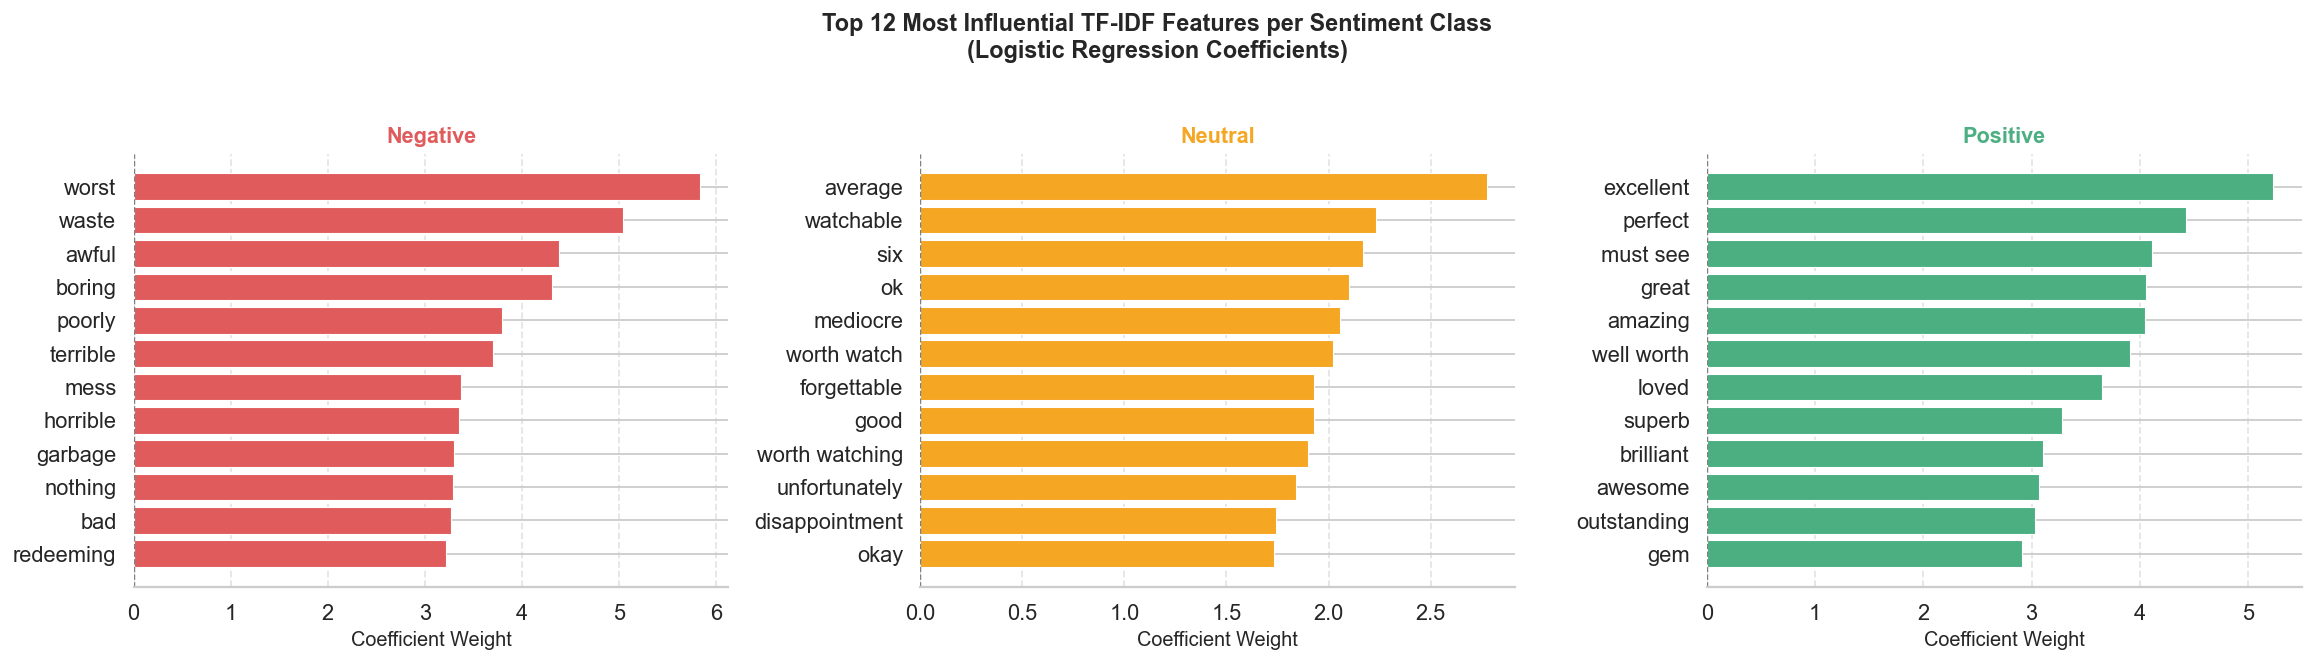

  Figure saved → 5_lr_top_features.png


In [16]:
# ── Top predictive features per class ────────────────────────────────────────
# Logistic Regression assigns a coefficient to each TF-IDF feature per class.
# Large positive coefficient = strong predictor FOR that class.
# Large negative coefficient = strong predictor AGAINST that class.

TOP_N_FEATURES = 12
classes        = lr_model.classes_

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
fig.suptitle(
    f'Top {TOP_N_FEATURES} Most Influential TF-IDF Features per Sentiment Class\n'
    '(Logistic Regression Coefficients)',
    fontsize=13, fontweight='bold', y=1.02
)

for ax, (cls_name, coefs) in zip(axes, zip(classes, lr_model.coef_)):
    # Get top N features with largest (positive) coefficients for this class
    top_idx  = np.argsort(coefs)[::-1][:TOP_N_FEATURES]
    top_feats = [feature_names[i] for i in top_idx]
    top_coefs = coefs[top_idx]

    colours = [PALETTE[cls_name]] * TOP_N_FEATURES

    bars = ax.barh(
        top_feats[::-1],   # reverse so highest is at top
        top_coefs[::-1],
        color     = colours,
        edgecolor = 'white',
        linewidth = 0.6,
    )

    ax.set_title(cls_name, color=PALETTE[cls_name], fontsize=12)
    ax.set_xlabel('Coefficient Weight')
    ax.axvline(0, color='grey', linewidth=0.8, linestyle='--')
    ax.xaxis.grid(True, linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)
    sns.despine(ax=ax, left=True)

plt.tight_layout()
plt.savefig('5_lr_top_features.png', dpi=150, bbox_inches='tight')
plt.show()
print('  Figure saved → 5_lr_top_features.png')

---
## Section 6 — Head-to-Head Comparison: VADER vs. Logistic Regression

This is the analytical centrepiece of Phase 2. We compare the two fundamentally different approaches:

| Dimension | VADER | Logistic Regression |
|-----------|-------|---------------------|
| **Paradigm** | Unsupervised / Rule-Based | Supervised / Statistical |
| **Training data needed** | ❌ None | ✅ Labelled examples |
| **Adapts to domain** | ❌ Fixed lexicon | ✅ Learns from movie reviews |
| **Interpretable** | ✅ Lexicon rules visible | ✅ Coefficients inspectable |
| **Deployment cost** | Very low | Low–Medium |
| **Neutral class handling** | ⚠️ Narrow band | Learned from data |

In [17]:
# ── Compute per-class F1 for both models ──────────────────────────────────────
vader_report_dict = classification_report(
    df['sentiment_label'],
    df['vader_prediction'],
    target_names  = LABEL_ORDER,
    zero_division = 0,
    output_dict   = True
)

lr_report_dict = classification_report(
    y_test, y_pred,
    target_names  = LABEL_ORDER,
    zero_division = 0,
    output_dict   = True
)

# ── Print the explicit comparison ─────────────────────────────────────────────
DIVIDER_WIDE = '═' * 70

print(DIVIDER_WIDE)
print('  HEAD-TO-HEAD COMPARISON: VADER vs. LOGISTIC REGRESSION')
print(DIVIDER_WIDE)
print()

# ── Overall accuracy ──────────────────────────────────────────────────────────
acc_diff   = (lr_accuracy - vader_accuracy) * 100
winner     = 'Logistic Regression' if lr_accuracy > vader_accuracy else 'VADER'
pct_better = abs(acc_diff)

print(f'  {'Metric':<30} {'VADER':>12}  {'Log. Reg.':>12}  {'Δ Diff':>10}')
print('  ' + '─' * 66)
print(f'  {'Overall Accuracy':<30} '
      f'{vader_accuracy*100:>11.2f}%  '
      f'{lr_accuracy*100:>11.2f}%  '
      f'{"+" if acc_diff >= 0 else ""}{acc_diff:>+9.2f}%')
print()

# ── Per-class F1 breakdown ────────────────────────────────────────────────────
print(f'  {'Per-Class F1-Score':<30} {'VADER':>12}  {'Log. Reg.':>12}  {'Δ Diff':>10}')
print('  ' + '─' * 66)
for label in LABEL_ORDER:
    vader_f1 = vader_report_dict[label]['f1-score']
    lr_f1    = lr_report_dict[label]['f1-score']
    diff     = (lr_f1 - vader_f1) * 100
    print(f'  {label + " F1":<30} '
          f'{vader_f1*100:>11.2f}%  '
          f'{lr_f1*100:>11.2f}%  '
          f'{"+" if diff >= 0 else ""}{diff:>+9.2f}%')


══════════════════════════════════════════════════════════════════════
  HEAD-TO-HEAD COMPARISON: VADER vs. LOGISTIC REGRESSION
══════════════════════════════════════════════════════════════════════

  Metric                                VADER     Log. Reg.      Δ Diff
  ──────────────────────────────────────────────────────────────────
  Overall Accuracy                     66.58%        79.54%  +   +12.96%

  Per-Class F1-Score                    VADER     Log. Reg.      Δ Diff
  ──────────────────────────────────────────────────────────────────
  Negative F1                          44.92%        73.48%  +   +28.57%
  Neutral F1                            1.73%        26.74%  +   +25.01%
  Positive F1                          79.20%        88.58%  +    +9.38%


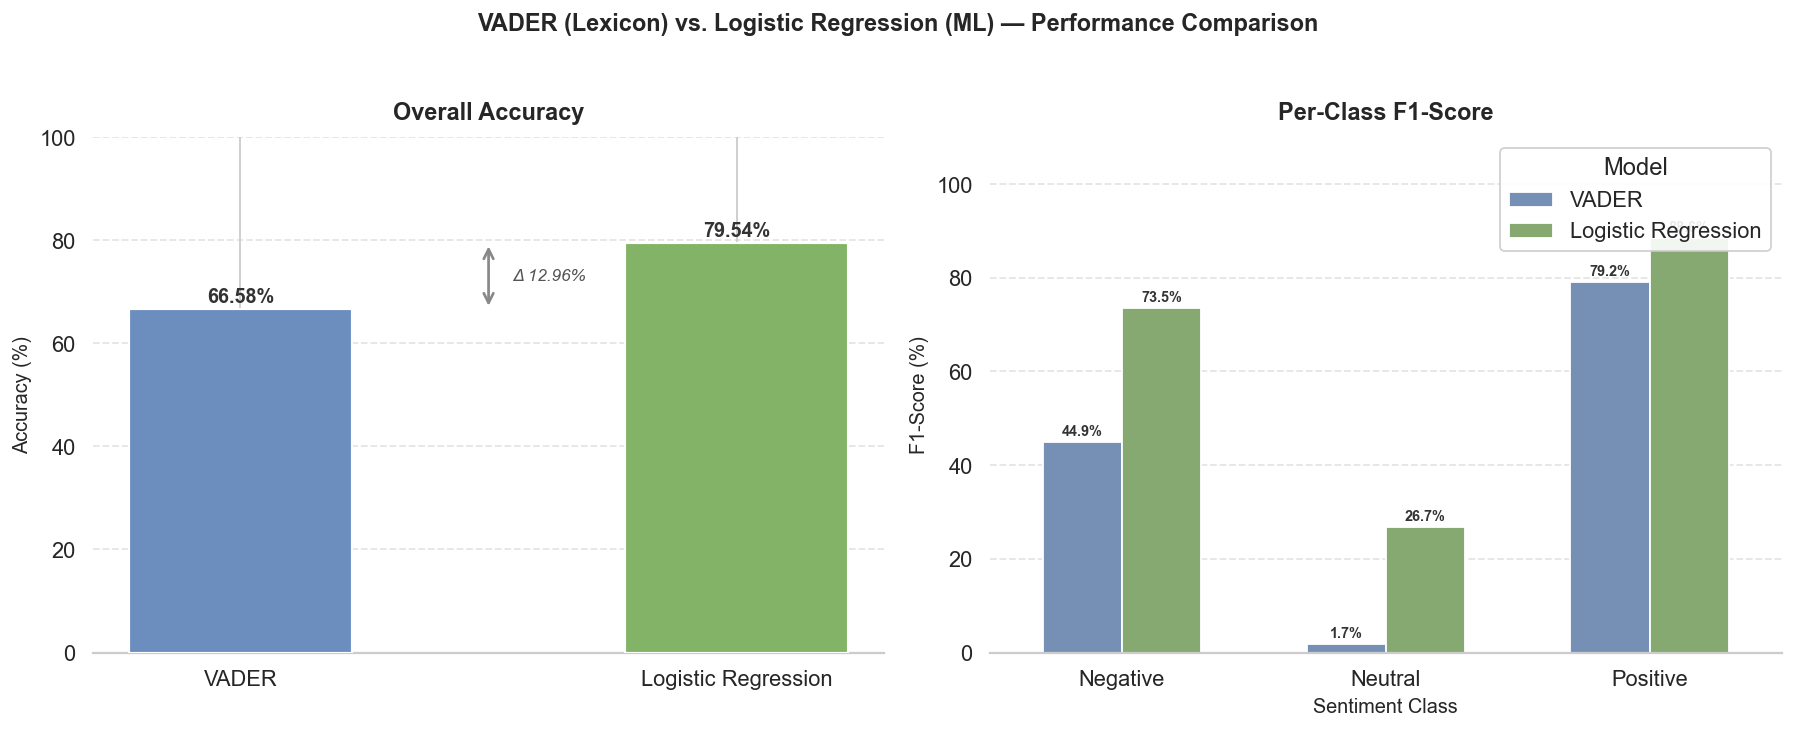

✅  Figure saved → 6_vader_vs_lr_comparison.png


In [18]:
# ── Visualise the comparison ──────────────────────────────────────────────────
# Two-panel figure:
#   Left  — Overall accuracy bar comparison
#   Right — Per-class F1 grouped bar chart

fig, (ax_acc, ax_f1) = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle(
    'VADER (Lexicon) vs. Logistic Regression (ML) — Performance Comparison',
    fontsize=13, fontweight='bold', y=1.02
)

MODEL_COLOURS = {'VADER': '#6C8EBF', 'Logistic Regression': '#82B366'}

# ── Panel A: Overall Accuracy ─────────────────────────────────────────────────
models       = ['VADER', 'Logistic Regression']
accuracies   = [vader_accuracy * 100, lr_accuracy * 100]
bar_colours  = [MODEL_COLOURS[m] for m in models]

bars = ax_acc.bar(
    models, accuracies,
    color     = bar_colours,
    edgecolor = 'white',
    linewidth = 1.2,
    width     = 0.45,
    zorder    = 3
)

# Annotate bars with accuracy values
for bar, acc in zip(bars, accuracies):
    ax_acc.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f'{acc:.2f}%',
        ha='center', va='bottom',
        fontsize=11, fontweight='bold', color='#333333'
    )

# Draw an arrow annotating the performance gap
y_min  = min(accuracies)
y_max  = max(accuracies)
x_mid  = 0.5
ax_acc.annotate(
    '',
    xy     = (x_mid, y_max),
    xytext = (x_mid, y_min),
    xycoords      = ('axes fraction', 'data'),
    textcoords    = ('axes fraction', 'data'),
    arrowprops    = dict(arrowstyle='<->', color='#888888', lw=1.5),
)
ax_acc.text(
    0.53, (y_min + y_max) / 2,
    f'Δ {abs(acc_diff):.2f}%',
    transform  = ax_acc.get_yaxis_transform(),
    ha='left', va='center',
    fontsize=9.5, color='#555555', fontstyle='italic'
)

ax_acc.set_title('Overall Accuracy', pad=10)
ax_acc.set_ylabel('Accuracy (%)')
ax_acc.set_ylim(0, 100)
ax_acc.yaxis.grid(True, linestyle='--', alpha=0.5, zorder=0)
ax_acc.set_axisbelow(True)
sns.despine(ax=ax_acc, left=True)

# ── Panel B: Per-class F1 ─────────────────────────────────────────────────────
f1_data = []
for label in LABEL_ORDER:
    f1_data.append({
        'Sentiment' : label,
        'Model'     : 'VADER',
        'F1-Score'  : vader_report_dict[label]['f1-score'] * 100
    })
    f1_data.append({
        'Sentiment' : label,
        'Model'     : 'Logistic Regression',
        'F1-Score'  : lr_report_dict[label]['f1-score'] * 100
    })

f1_df = pd.DataFrame(f1_data)

sns.barplot(
    data      = f1_df,
    x         = 'Sentiment',
    y         = 'F1-Score',
    hue       = 'Model',
    order     = LABEL_ORDER,
    palette   = MODEL_COLOURS,
    edgecolor = 'white',
    linewidth = 1.0,
    width     = 0.6,
    ax        = ax_f1,
)

# Add value labels on each grouped bar
for container in ax_f1.containers:
    ax_f1.bar_label(container, fmt='%.1f%%', fontsize=8,
                    padding=2, fontweight='bold', color='#333333')

ax_f1.set_title('Per-Class F1-Score', pad=10)
ax_f1.set_xlabel('Sentiment Class')
ax_f1.set_ylabel('F1-Score (%)')
ax_f1.set_ylim(0, 110)
ax_f1.yaxis.grid(True, linestyle='--', alpha=0.5, zorder=0)
ax_f1.set_axisbelow(True)
ax_f1.legend(title='Model', loc='upper right', framealpha=0.9)
sns.despine(ax=ax_f1, left=True)

plt.tight_layout()
plt.savefig('6_vader_vs_lr_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅  Figure saved → 6_vader_vs_lr_comparison.png')

---
## Section 7 — Transformer model training


In [3]:
import torch
import numpy as np
import evaluate
import accelerate
from datasets import Dataset
from transformers import (
    AutoTokenizer, 
    AutoModelForSequenceClassification, 
    TrainingArguments, 
    Trainer,
    DataCollatorWithPadding
)

In [18]:
# 1. Verify GPU availability
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
if device == "cpu":
    print("WARNING: No GPU detected! BERT training will be extremely slow. Switch your runtime to GPU.")

Using device: cuda


In [5]:
relevant_df= df[['cleaned_text', 'sentiment_label']].copy()

In [6]:
# 2. Extract arrays and map string labels ('negative', 'neutral', 'positive') to integers
label_mapping = {'Negative': 0, 'Neutral': 1, 'Positive': 2}

texts = relevant_df['cleaned_text'].astype(str).tolist()
labels = [label_mapping[lbl] for lbl in relevant_df['sentiment_label']]

In [7]:
# Extract a small balanced 15,000 row subset to guarantee lightning speed
_, X_small, _, y_small = train_test_split(
    texts, labels, test_size=15000, stratify=labels, random_state=42
)

# Split subset into 80% Train / 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X_small, y_small, test_size=0.20, stratify=y_small, random_state=42
)

In [8]:
# 4. Construct light-weight Hugging Face Datasets from the split columns
train_dataset = Dataset.from_dict({"text": X_train, "label": y_train})
test_dataset = Dataset.from_dict({"text": X_test, "label": y_test})

In [9]:
# 5. Tokenize using 'bert-base-uncased'
model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [10]:
def tokenize_function(examples):
    # max_length=256 significantly improves training speeds over 512
    return tokenizer(examples["text"], truncation=True, max_length=256)

print("Tokenizing isolated columns...")
tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_test = test_dataset.map(tokenize_function, batched=True)

Tokenizing isolated columns...


Map: 100%|██████████| 3000/3000 [00:00<00:00, 5118.22 examples/s]


In [11]:
# Pads arrays dynamically to the longest element in a batch (saves matrix memory)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [31]:
# 6. Initialize BERT Model (Targeting 3 classes)
device = ""
if torch.cuda.is_available() :
    device= "cuda"
    print("cuda is available")
else:
    "cpu"
model = AutoModelForSequenceClassification.from_pretrained(
    model_name, 
    num_labels=3
).to(device)

cuda is available


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2163.68it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

In [32]:
# 7. Setup standard Macro F1 evaluation metric
metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels, average="macro")

In [33]:
# 8. Low-Intensity Training Arguments
training_args = TrainingArguments(
    ignore_data_skip=True,
    output_dir="./bert_fast_model",
    learning_rate=3e-5,                  
    per_device_train_batch_size=32,     # Maximizes parallel computing capability
    per_device_eval_batch_size=32,
    num_train_epochs=1,                 # Only 1 pass over the small subset
    weight_decay=0.01,
    eval_strategy="no",                 
    save_strategy="no",                 
    fp16=torch.cuda.is_available(),     # Activates dynamic half-precision floating point math
    logging_steps=50,
    report_to="none"
)

In [34]:
# 9. Initialize and Train
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [35]:
# 9. Clear explicit memory and force initialize
import gc
torch.cuda.empty_cache() if torch.cuda.is_available() else None
gc.collect()

2546

In [36]:
if torch.cuda.is_available():
    model = model.to("cuda:0")

In [37]:
print(f"Starting BERT training on device: {device}")
trainer.train()

Starting BERT training on device: cuda


Step,Training Loss
50,0.828164
100,0.658688


KeyboardInterrupt: 